### Import Library

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_validate
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

### Load Data Label Manual & RoBERTa

In [2]:
MANUAL_PATH = '../../data/labeled/manual_labeling.csv'
ROBERTA_PATH = '../../data/labeled/roberta_labeled.csv'

df_manual = pd.read_csv(MANUAL_PATH, encoding="utf-8-sig")

df_roberta = pd.read_csv(ROBERTA_PATH, encoding="utf-8-sig")

df_manual.columns = df_manual.columns.str.strip()
df_roberta.columns = df_roberta.columns.str.strip()

print("Data manual:", df_manual.shape)
print("Data RoBERTa:", df_roberta.shape)

print("\nKolom manual:")
print(df_manual.columns.tolist())

print("\nKolom RoBERTa:")
print(df_roberta.columns.tolist())

Data manual: (8790, 2)
Data RoBERTa: (48546, 4)

Kolom manual:
['text', 'label']

Kolom RoBERTa:
['text', 'original_text', 'clean_text', 'label_roberta']


### Merapihkan Nama Label

In [3]:
def normalize_label(label):
    label = str(label).strip().lower()

    mapping = {
        "negative": "negative",
        "negatif": "negative",
        "neg": "negative",

        "positive": "positive",
        "positif": "positive",
        "pos": "positive",

        "neutral": "neutral",
        "netral": "neutral",
        "neu": "neutral"
    }

    return mapping.get(label, label)


df_manual["label_manual"] = df_manual["label"].apply(normalize_label)
df_roberta["label_roberta"] = df_roberta["label_roberta"].apply(normalize_label)

print("Distribusi label manual:")
print(df_manual["label_manual"].value_counts())

print("\nDistribusi label roberta:")
print(df_roberta ["label_roberta"].value_counts())

Distribusi label manual:
label_manual
negative    6043
positive    1691
neutral     1056
Name: count, dtype: int64

Distribusi label roberta:
label_roberta
negative    28209
neutral     11228
positive     9109
Name: count, dtype: int64


### Menggabungkan data manual dengan hasil RoBERTa

Karena file label manual berisi 8.790 data, sedangkan RoBERTa berisi 48.546 data, maka bagian yang dibandingkan adalah 8.790 data pertama.

In [4]:
n_manual = len(df_manual)

df_manual_subset = df_manual.copy().reset_index(drop=True)
df_roberta_subset = df_roberta.iloc[:n_manual].copy().reset_index(drop=True)

df_svm_roberta = pd.DataFrame({
    "manual_text": df_manual_subset["text"],
    "clean_text": df_roberta_subset["clean_text"],
    "label_manual": df_manual_subset["label_manual"],
    "label_roberta": df_roberta_subset["label_roberta"]
})

df_svm_roberta["clean_text"] = df_svm_roberta["clean_text"].fillna("").astype(str)
df_svm_roberta = df_svm_roberta[df_svm_roberta["clean_text"].str.strip() != ""]

print("Jumlah data siap pakai:", len(df_svm_roberta))

df_svm_roberta.head()

Jumlah data siap pakai: 8784


,manual_text,clean_text,label_manual,label_roberta
0,adil jokowi,adil jokowi,negative,negative
1,moga pak prabowo tidak kayak begini pak,moga pak prabowo tidak kayak begini pak,neutral,negative
2,siap siap mulyono semua panggil,siap siap mulyono semua panggil,negative,neutral
3,pilih foto biar kesan siapa tuan,pilih foto biar kesan siapa tuan,negative,negative
4,lo bayar nih utang,lo bayar nih utang,negative,neutral


### Menampilkan sampel data hasil penggabungan label manual dan label IndoBERT

In [5]:
df_svm_roberta[[
    "manual_text",
    "clean_text",
    "label_manual",
    "label_roberta"
]].head(20)

,manual_text,clean_text,label_manual,label_roberta
0,adil jokowi,adil jokowi,negative,negative
1,moga pak prabowo tidak kayak begini pak,moga pak prabowo tidak kayak begini pak,neutral,negative
2,siap siap mulyono semua panggil,siap siap mulyono semua panggil,negative,neutral
3,pilih foto biar kesan siapa tuan,pilih foto biar kesan siapa tuan,negative,negative
4,lo bayar nih utang,lo bayar nih utang,negative,neutral
5,ijazah kamu mana wi,ijazah kamu mana wi,negative,negative
6,jangan jadi indonesia pernah tipu satu keluarg...,jangan jadi indonesia pernah tipu satu keluarg...,negative,negative
7,sir kok lebih tarik pinjam bunga lebih tinggi ...,sir kok lebih tarik pinjam bunga lebih tinggi ...,negative,negative
8,waris susah presiden sekarang pak,waris susah presiden sekarang pak,negative,negative
9,halo pak,halo pak,neutral,neutral


### Split Data 80% 20%

In [6]:
X = df_svm_roberta["clean_text"]

y_manual = df_svm_roberta["label_manual"]
y_roberta = df_svm_roberta["label_roberta"]

indices = np.arange(len(df_svm_roberta))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=y_manual
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

# Bagian utama:
# SVM dilatih menggunakan label roberta
y_train = y_roberta.iloc[train_idx]

# SVM diuji menggunakan label manual
y_test = y_manual.iloc[test_idx]

print("Jumlah data train:", len(X_train))
print("Jumlah data test :", len(X_test))

print("\nDistribusi y_train label RoBERTa:")
print(y_train.value_counts())

print("\nDistribusi y_test label manual:")
print(y_test.value_counts())

Jumlah data train: 7027
Jumlah data test : 1757

Distribusi y_train label RoBERTa:
label_roberta
negative    4233
positive    1397
neutral     1397
Name: count, dtype: int64

Distribusi y_test label manual:
label_manual
negative    1208
positive     338
neutral      211
Name: count, dtype: int64


### Training Model SVM dengan Label RoBERTa

In [7]:
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("svm", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

param_grid = {
    'svm__C': [0.01, 0.1, 1, 10, 100]
}

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameter :", grid.best_params_)
print("Best Score :", grid.best_score_)

svm_roberta_model = grid.best_estimator_

Best Parameter : {'svm__C': 0.1}
Best Score : 0.6775586274175953


### Evaluasi terhadap label manual

In [8]:
y_pred = svm_roberta_model.predict(X_test)

labels_order = ["negative", "neutral", "positive"]

accuracy = accuracy_score(y_test, y_pred)

precision_macro = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
recall_macro = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
f1_macro = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

precision_weighted = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)
recall_weighted = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)
f1_weighted = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

print("HASIL EVALUASI SVM LABEL ROBERTA TERHADAP LABEL MANUAL")
print("=" * 70)
print(f"Accuracy           : {accuracy:.4f}")
print(f"Macro Precision    : {precision_macro:.4f}")
print(f"Macro Recall       : {recall_macro:.4f}")
print(f"Macro F1-score     : {f1_macro:.4f}")
print(f"Weighted Precision : {precision_weighted:.4f}")
print(f"Weighted Recall    : {recall_weighted:.4f}")
print(f"Weighted F1-score  : {f1_weighted:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=labels_order,
    zero_division=0
))

HASIL EVALUASI SVM LABEL ROBERTA TERHADAP LABEL MANUAL
Accuracy           : 0.6898
Macro Precision    : 0.5605
Macro Recall       : 0.5536
Macro F1-score     : 0.5531
Weighted Precision : 0.7059
Weighted Recall    : 0.6898
Weighted F1-score  : 0.6961

Classification Report:
              precision    recall  f1-score   support

    negative       0.81      0.80      0.81      1208
     neutral       0.27      0.36      0.31       211
    positive       0.60      0.50      0.55       338

    accuracy                           0.69      1757
   macro avg       0.56      0.55      0.55      1757
weighted avg       0.71      0.69      0.70      1757



In [9]:
import pandas as pd

hasil_roberta = pd.DataFrame({
    'y_test': y_test.reset_index(drop=True),
    'y_pred_roberta': y_pred
})

hasil_roberta.to_csv('hasil_roberta.csv', index=False)

print("Berhasil disimpan!")

Berhasil disimpan!


### Confusion Matrix

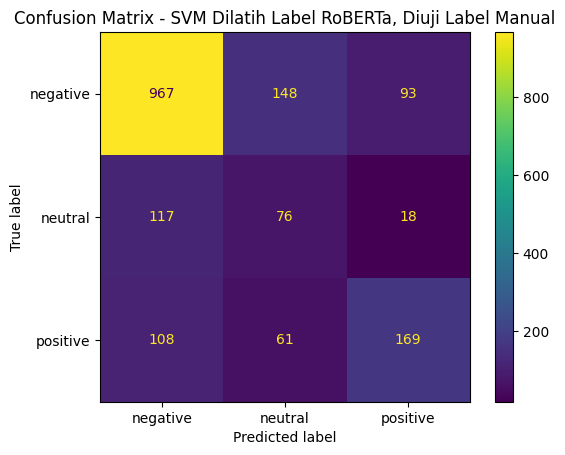

In [10]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels_order
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels_order
)

disp.plot(values_format="d")
plt.title("Confusion Matrix - SVM Dilatih Label RoBERTa, Diuji Label Manual")
plt.show()

### Analisis Eror

In [11]:
error_df = pd.DataFrame({
    'text': X_test.reset_index(drop=True),
    'label_manual': y_test.reset_index(drop=True),
    'prediksi_svm': pd.Series(y_pred)
})

error_df = error_df[
    error_df['label_manual'] != error_df['prediksi_svm']
]

print(f"Jumlah salah klasifikasi: {len(error_df)}")

error_df.head(20)

Jumlah salah klasifikasi: 604


,text,label_manual,prediksi_svm
2,bukan jokowi,positive,negative
13,nderek mangayubagya sugeng ambal warsa ingkang...,positive,neutral
14,harum nama bangsa,neutral,negative
17,video lucu,positive,neutral
20,terus doa paus apa pak lihat foto bpak doa,negative,neutral
22,mau reuni kali hari kaya orang makan tidak yak...,neutral,negative
26,tamak,negative,neutral
29,ayo tunjuk ijazah asli kau,neutral,negative
33,ngumpet mana pak,negative,neutral
36,sebentar sembah deh,neutral,negative


### Mengidentifikasi pola kesalahan klasifikasi antar kelas sentimen

In [12]:
error_df['jenis_error'] = (
    error_df['label_manual']
    + ' → ' +
    error_df['prediksi_svm']
)

error_summary = error_df['jenis_error'].value_counts()

print(error_summary)

jenis_error
negative → neutral     187
negative → positive    127
neutral → negative     101
positive → negative     94
positive → neutral      71
neutral → positive      24
Name: count, dtype: int64


### Evaluasi stabilitas model menggunakan 5-Fold Cross Validation

In [13]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted"
}

cv_results = cross_validate(
    svm_roberta_model,
    X,
    y_roberta,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("HASIL 5-FOLD CROSS VALIDATION")
print("=" * 70)

print(
    f"Accuracy      : "
    f"{cv_results['test_accuracy'].mean():.4f} ± "
    f"{cv_results['test_accuracy'].std():.4f}"
)

print(
    f"Macro F1      : "
    f"{cv_results['test_f1_macro'].mean():.4f} ± "
    f"{cv_results['test_f1_macro'].std():.4f}"
)

print(
    f"Weighted F1   : "
    f"{cv_results['test_f1_weighted'].mean():.4f} ± "
    f"{cv_results['test_f1_weighted'].std():.4f}"
)

HASIL 5-FOLD CROSS VALIDATION
Accuracy      : 0.7409 ± 0.0036
Macro F1      : 0.6809 ± 0.0061
Weighted F1   : 0.7379 ± 0.0041


In [14]:
cv_df = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": cv_results["test_accuracy"],
    "Macro_F1": cv_results["test_f1_macro"],
    "Weighted_F1": cv_results["test_f1_weighted"]
})

cv_df

,Fold,Accuracy,Macro_F1,Weighted_F1
0,1,0.747866,0.692232,0.745950
1,2,0.737621,0.680609,0.736136
2,3,0.738759,0.679565,0.735145
3,4,0.739898,0.677382,0.735638
4,5,0.740319,0.674479,0.736669
